In [1]:
import os
os.environ["XLA_FLAGS"] = "--xla_gpu_cuda_data_dir=/usr/local/cuda-13.0"
import tensorflow as tf

I0000 00:00:1792112680.124424   38333 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792112680.162933   38333 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792112681.428660   38333 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import os
print(os.environ.get("XLA_FLAGS"))

--xla_gpu_cuda_data_dir=/usr/local/cuda-13.0


In [3]:
# Run FIRST, before any other cell
import subprocess, os

# Check NVIDIA driver
try:
    out = subprocess.check_output(["nvidia-smi"], text=True)
    print(out[:500])
except FileNotFoundError:
    print("nvidia-smi not found — no NVIDIA driver installed or no GPU present.")

# Check environment
print("CUDA_VISIBLE_DEVICES:", repr(os.environ.get("CUDA_VISIBLE_DEVICES")))
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH", "(not set)"))

# Check TF build
import tensorflow as tf
print("\nTF version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("Physical GPUs:", tf.config.list_physical_devices("GPU"))
print("All devices:", tf.config.list_physical_devices())

Thu Oct 15 20:04:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.173.02             Driver Version: 580.173.02     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|       
CUDA_VISIBLE_DEVICES: None
LD_LIBRARY_PATH: (not set)

TF version: 2.21.0
Built with CUDA: True
Physical GPUs: []
All devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


W0000 00:00:1792112682.824282   38333 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [4]:
# Imports
import os, re, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
from gaussiannb_model import GaussianNBTF, save_model

In [5]:
import os, tensorflow as tf
print("TF:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))

TF: 2.21.0
Built with CUDA: True
Visible GPUs: []
CUDA_VISIBLE_DEVICES: None


In [6]:
import tensorflow as tf
print(tf.__version__)
print(tf.test.is_built_with_cuda())
print(tf.config.list_physical_devices("GPU"))

2.21.0
True
[]


In [7]:
# Configuration
from pathlib import Path

# Option 1: absolute path (quickest)
data_root = Path("/home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean")   # this repo's copy (identical to the forked checkout's)

# Option 2: repo-relative (more portable)
# data_root = (Path.cwd().resolve().parents[1] / "Data_clean")

import sys
sys.path.insert(0, str(Path.cwd().parent))  # prediction-gaussiannb/eeg_data.py
from eeg_data import LoadConfig, load_recordings, recordings_to_frame

# Verified loading (prediction-gaussiannb/eeg_data.py): named OpenBCI recordings with the EEG
# channels selected by header name, one board configuration, folder labels normalised
# ("TakOff", "Take off", "backard", ... are kept), quality-filtered 2 s blocks (the start-up block
# is always dropped), then a 1-40 Hz band-pass and 60 Hz notch on each kept segment.
# Channel 15 is excluded because it was dead for 6 participants.
LOAD_CONFIG = LoadConfig(board="16ch_125hz", exclude_channels=("EXG Channel 15",),
                         quality_filter=True, bandpass_hz=(1.0, 40.0), notch_hz=60.0)
use_pca = True
pca_components = 32
var_smoothing = 1e-9

print("data_root:", data_root)
print("exists:", data_root.exists())
print("txt files found:", sum(1 for _ in data_root.rglob("*.txt")))

data_root: /home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean
exists: True
txt files found: 1827


In [8]:
# Load verified recordings (replaces the positional 16-column loader, which read accelerometer and
# digital-pin columns as EEG for 8-channel files and also read headerless BrainFlow exports)
recordings, skipped = load_recordings(data_root, LOAD_CONFIG)
eeg_data = recordings_to_frame(recordings)
failed = [r["path"] for r in skipped]

print("Loaded files:", eeg_data["src_filename"].nunique())
print("Skipped recordings:", len(failed))
print("eeg_data shape:", eeg_data.shape)
print("Columns:", eeg_data.columns.tolist()[:20])


Files under root: 3648; named OpenBCI recordings: 1826; recorded sessions: 0 (0 trials)
Board 16ch_125hz: 1394 recordings loaded, 432 skipped (other board or unreadable); headerless exports are not read
Channels used (15): excluded ['EXG Channel 15']
2 s blocks kept: 3249/6703 (48.5%), recordings with usable data: 883/1394
Participants with usable data: 18/23 (none usable: G03/person02, G04/person03, G04/person06, G04/person08, G04/person10)
Loaded files: 883
Skipped recordings: 432
eeg_data shape: (812250, 19)
Columns: ['EXG Channel 0', 'EXG Channel 1', 'EXG Channel 2', 'EXG Channel 3', 'EXG Channel 4', 'EXG Channel 5', 'EXG Channel 6', 'EXG Channel 7', 'EXG Channel 8', 'EXG Channel 9', 'EXG Channel 10', 'EXG Channel 11', 'EXG Channel 12', 'EXG Channel 13', 'EXG Channel 14', 'src_filename', 'segment_id', 'participant_id', 'label_txt']


In [9]:
# Labels come from the action folder (eeg_data.py uses signal_quality.salvage.folder_label), so
# variant folder names such as "TakOff", "Take off", "Foreward" and "backard" are labelled, not dropped.
assert not eeg_data.empty, "No data loaded."

print("Label distribution (samples):")
print(eeg_data["label_txt"].value_counts(dropna=False))


Label distribution (samples):
label_txt
takeoff     152500
landing     142500
left        133500
right       131750
backward    126250
forward     125750
Name: count, dtype: int64


GaussianNB on Raw Data: val=0.2003, test=0.1842, vs=1.0e-12
GaussianNB with PCA + PowerTransformer: val=0.2303, test=0.1965, vs=1.0e-12
GaussianNB on Frequency Features (PSD log-rel): val=0.2282, test=0.2254, vs=1.0e-12

Comparative results:
                                       Experiment  Val_Acc_Window  \
0  GaussianNB on Frequency Features (PSD log-rel)        0.228180   
1          GaussianNB with PCA + PowerTransformer        0.230258   
2                          GaussianNB on Raw Data        0.200333   

   Test_Acc_Window  Test_Acc_File  Best_var_smoothing  Dim_before  Dim_after  \
0         0.225382       0.248588        1.000000e-12         120         43   
1         0.196520       0.175141        1.000000e-12        1875        396   
2         0.184211       0.186441        1.000000e-12        1875       1875   

   Train_windows  Val_windows  Test_windows  
0           7327         2406          2356  
1           7327         2406          2356  
2           7327      

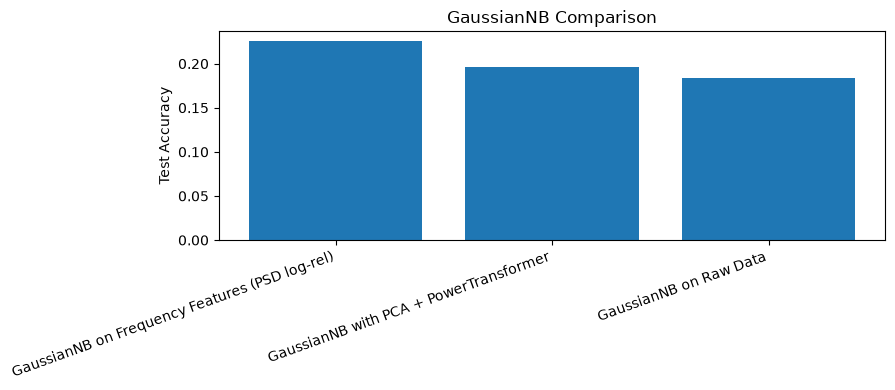


Best experiment: GaussianNB on Frequency Features (PSD log-rel)
Confusion matrix:
 [[ 77  53  58  59  64  46]
 [ 67  60  38  61  87  62]
 [ 34  32 117  75  57  81]
 [ 41  35  57  85  71  61]
 [ 31  32  67  79  94  88]
 [ 61  49  74  95 110  98]]

Classification report:
               precision    recall  f1-score   support

    backward       0.25      0.22      0.23       357
     forward       0.23      0.16      0.19       375
     landing       0.28      0.30      0.29       396
        left       0.19      0.24      0.21       350
       right       0.19      0.24      0.22       391
     takeoff       0.22      0.20      0.21       487

    accuracy                           0.23      2356
   macro avg       0.23      0.23      0.22      2356
weighted avg       0.23      0.23      0.22      2356



In [10]:
# Grouped-window experiments for GaussianNBTF
# Compares:
# 1) Raw window baseline
# 2) Raw + PowerTransformer + PCA(95%)
# 3) PSD band powers (+ optional Power/PCA, here enabled)

import copy
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import welch
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import QuantileTransformer

sys.path.insert(0, str(Path.cwd().parent))  # prediction-gaussiannb/fast_preprocessing.py
from fast_preprocessing import ParallelPowerTransformer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

# ---------------------------
# 1) Config
# ---------------------------
fs = int(LOAD_CONFIG.sfreq)  # 125 Hz for the 16-channel board
window_size = 125
window_stride = 62   # true ~50% overlap for ws=125
var_smoothing_grid = np.logspace(-12, -2, 11)
random_state = 42

bands = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 45.0),
}

# ---------------------------
# 2) Validation + grouped split by file
# ---------------------------
required_cols = {"src_filename", "label_txt"}
if not required_cols.issubset(set(eeg_data.columns)):
    raise ValueError("eeg_data must contain src_filename and label_txt")

exg_cols = [f"EXG Channel {i}" for i in range(16) if f"EXG Channel {i}" in eeg_data.columns]
if len(exg_cols) < 8:
    raise ValueError(f"Expected EXG columns, found only {len(exg_cols)}")

df = eeg_data.copy()
df = df[df["label_txt"].astype(str).str.len() > 0].copy()
df = df[["src_filename", "segment_id", "label_txt"] + exg_cols].copy()
df[exg_cols] = df[exg_cols].apply(pd.to_numeric, errors="coerce")
df[exg_cols] = df[exg_cols].replace([np.inf, -np.inf], np.nan)

file_label = df.groupby("src_filename")["label_txt"].agg(
    lambda s: s.mode().iat[0] if not s.mode().empty else s.iloc[0]
)

files = file_label.index.to_numpy()
file_labels_txt = file_label.values
label_names = sorted(pd.unique(file_labels_txt).tolist())
label_to_id = {lbl: i for i, lbl in enumerate(label_names)}
file_labels = np.array([label_to_id[x] for x in file_labels_txt], dtype=np.int32)

# 60/20/20 split at FILE level (train/val/test)
trainval_files, test_files = train_test_split(
    files, test_size=0.2, random_state=random_state, stratify=file_labels
)
trainval_labels = np.array([label_to_id[file_label.loc[f]] for f in trainval_files], dtype=np.int32)

train_files, val_files = train_test_split(
    trainval_files, test_size=0.25, random_state=random_state, stratify=trainval_labels
)

train_file_set = set(train_files)
train_rows = df[df["src_filename"].isin(train_file_set)]
train_medians = train_rows[exg_cols].median(numeric_only=True)

# ---------------------------
# 3) Feature extractors
# ---------------------------
def feat_raw_flatten(win_2d):
    # raw time-series values as features (channels concatenated in time)
    return win_2d.reshape(-1).astype(np.float32)

def feat_time_stats(win_2d):
    # your previous handcrafted stats baseline
    mean = np.mean(win_2d, axis=0)
    std = np.std(win_2d, axis=0)
    vmin = np.min(win_2d, axis=0)
    vmax = np.max(win_2d, axis=0)
    ptp = vmax - vmin
    energy = np.mean(win_2d * win_2d, axis=0)
    line_len = np.mean(np.abs(np.diff(win_2d, axis=0)), axis=0)
    return np.concatenate([mean, std, vmin, vmax, ptp, energy, line_len]).astype(np.float32)

def feat_psd_bands_logrel(win_2d, sfreq=fs):
    # Welch PSD per channel: psd shape [freq_bins, channels]
    freqs, psd = welch(
        win_2d,
        fs=sfreq,
        nperseg=min(256, win_2d.shape[0]),
        noverlap=min(128, max(0, win_2d.shape[0] // 2)),
        axis=0
    )
    eps = 1e-12

    # Total power in analysis range (for relative powers)
    total_idx = (freqs >= 0.5) & (freqs < 45.0)
    total_power = np.trapezoid(psd[total_idx, :], freqs[total_idx], axis=0) + eps

    band_abs = []
    band_rel_log = []

    for lo, hi in bands.values():
        idx = (freqs >= lo) & (freqs < hi)
        if np.any(idx):
            bp = np.trapezoid(psd[idx, :], freqs[idx], axis=0)
        else:
            bp = np.zeros(win_2d.shape[1], dtype=np.float32)

        rel = bp / total_power
        band_abs.append(bp.astype(np.float32))
        band_rel_log.append(np.log1p(rel).astype(np.float32))

    # Unpack for ratios (order must match your bands dict)
    delta, theta, alpha, beta, gamma = band_abs

    # Common EEG ratios (with safe denom)
    theta_beta = theta / (beta + eps)
    alpha_beta = alpha / (beta + eps)
    theta_alpha = theta / (alpha + eps)

    # Final PSD feature vector:
    # 1) log-relative band powers
    # 2) selected band ratios
    return np.concatenate(
        band_rel_log + [
            np.log1p(theta_beta).astype(np.float32),
            np.log1p(alpha_beta).astype(np.float32),
            np.log1p(theta_alpha).astype(np.float32),
        ]
    ).astype(np.float32)


def feat_psd_bands_logrel_batch(windows, sfreq=fs):
    """feat_psd_bands_logrel for a stack of windows shaped (n_windows, ws, channels) in one welch call."""
    ws = windows.shape[1]
    freqs, psd = welch(
        windows,
        fs=sfreq,
        nperseg=min(256, ws),
        noverlap=min(128, max(0, ws // 2)),
        axis=1
    )
    eps = 1e-12
    total_idx = (freqs >= 0.5) & (freqs < 45.0)
    total_power = np.trapezoid(psd[:, total_idx, :], freqs[total_idx], axis=1) + eps

    band_abs, band_rel_log = [], []
    for lo, hi in bands.values():
        idx = (freqs >= lo) & (freqs < hi)
        if np.any(idx):
            bp = np.trapezoid(psd[:, idx, :], freqs[idx], axis=1)
        else:
            bp = np.zeros((windows.shape[0], windows.shape[2]), dtype=np.float32)
        band_abs.append(bp.astype(np.float32))
        band_rel_log.append(np.log1p(bp / total_power).astype(np.float32))

    delta, theta, alpha, beta, gamma = band_abs
    return np.concatenate(
        band_rel_log + [
            np.log1p(theta / (beta + eps)).astype(np.float32),
            np.log1p(alpha / (beta + eps)).astype(np.float32),
            np.log1p(theta / (alpha + eps)).astype(np.float32),
        ],
        axis=1
    ).astype(np.float32)

def feat_raw_flatten_batch(windows):
    """feat_raw_flatten for a stack of windows shaped (n_windows, ws, channels)."""
    return windows.reshape(windows.shape[0], -1).astype(np.float32)

# build_window_dataset uses the batched version when a feature function provides one
feat_raw_flatten.batch = feat_raw_flatten_batch
feat_psd_bands_logrel.batch = feat_psd_bands_logrel_batch

_signal_cache = {}
_window_cache = {}

def _file_signals(medians):
    """Kept segments of every file as float32 arrays (samples, channels), computed once per medians object."""
    cached = _signal_cache.get(id(medians))
    if cached is None or cached[0] is not medians:
        sig_all = df[exg_cols].fillna(medians).fillna(0.0).to_numpy(dtype=np.float32)
        seg = df["segment_id"].to_numpy()
        files_col = df["src_filename"].to_numpy()
        order = np.argsort(seg, kind="stable")
        by_file = {}
        for idx in np.split(order, np.flatnonzero(np.diff(seg[order])) + 1):
            by_file.setdefault(files_col[idx[0]], []).append(sig_all[idx])
        cached = (medians, by_file)
        _signal_cache[id(medians)] = cached
    return cached[1]

def build_window_dataset(file_list, medians, ws, stride, feature_fn):
    # Windows are cut within each kept segment, so a window never spans a rejected 2 s block.
    # Each file's windows are built as one (n_windows, ws, channels) array, and results are cached.
    # The returned arrays are shared between calls: do not modify them in place.
    key = (tuple(file_list), id(medians), ws, stride, feature_fn.__name__)
    if key in _window_cache:
        return _window_cache[key]

    signals = _file_signals(medians)
    batch_fn = getattr(feature_fn, "batch", None)
    X_list, y_list, file_idx_list = [], [], []
    used_files, short_files = 0, 0

    for file_idx, fp in enumerate(file_list):
        segs = [s for s in signals.get(fp, []) if s.shape[0] >= ws]
        if not segs:
            if fp in signals:
                short_files += 1
            continue

        # windows starting at 0, stride, 2*stride, ... within each segment -> (n_windows, ws, channels)
        windows = np.concatenate([sliding_window_view(s, ws, axis=0)[::stride].transpose(0, 2, 1) for s in segs])
        if batch_fn is not None:
            feats = batch_fn(windows)
        else:
            feats = np.stack([feature_fn(win) for win in windows])
        lbl_id = label_to_id[file_label.loc[fp]]
        X_list.append(feats)
        y_list.append(np.full(len(windows), lbl_id, dtype=np.int32))
        file_idx_list.append(np.full(len(windows), file_idx, dtype=np.int32))
        used_files += 1

    if not X_list:
        raise ValueError("No windows generated. Reduce window_size or inspect file lengths.")

    X = np.vstack(X_list).astype(np.float32)
    y = np.concatenate(y_list).astype(np.int32)
    file_ids = np.concatenate(file_idx_list).astype(np.int32)
    _window_cache[key] = (X, y, file_ids, used_files, short_files)
    return _window_cache[key]

    signals = _file_signals(medians)
    batch_fn = getattr(feature_fn, "batch", None)
    X_list, y_list, file_idx_list = [], [], []
    used_files, short_files = 0, 0

    for file_idx, fp in enumerate(file_list):
        sig = signals.get(fp)
        if sig is None or sig.shape[0] == 0:
            continue
        n = sig.shape[0]
        if n < ws:
            short_files += 1
            continue

        # windows starting at 0, stride, 2*stride, ... -> (n_windows, ws, channels)
        windows = sliding_window_view(sig, ws, axis=0)[::stride].transpose(0, 2, 1)
        if batch_fn is not None:
            feats = batch_fn(windows)
        else:
            feats = np.stack([feature_fn(win) for win in windows])
        lbl_id = label_to_id[file_label.loc[fp]]
        X_list.append(feats)
        y_list.append(np.full(len(windows), lbl_id, dtype=np.int32))
        file_idx_list.append(np.full(len(windows), file_idx, dtype=np.int32))
        used_files += 1

    if not X_list:
        raise ValueError("No windows generated. Reduce window_size or inspect file lengths.")

    X = np.vstack(X_list).astype(np.float32)
    y = np.concatenate(y_list).astype(np.int32)
    file_ids = np.concatenate(file_idx_list).astype(np.int32)
    _window_cache[key] = (X, y, file_ids, used_files, short_files)
    return _window_cache[key]

# ---------------------------
# 4) Preprocessing helpers (Gaussianization + PCA)
# ---------------------------
def fit_preprocess(X_train, gaussianizer="none", pca_var=None):
    state = {"gaussianizer": gaussianizer, "transformer": None, "mu": None, "sd": None, "pca": None}

    if gaussianizer == "power":
        # identical to sklearn's PowerTransformer, with the per-feature fits run in parallel
        tr = ParallelPowerTransformer(method="yeo-johnson", standardize=True)
        Xp = tr.fit_transform(X_train)
        state["transformer"] = tr
    elif gaussianizer == "quantile":
        n_q = int(min(1000, X_train.shape[0]))
        tr = QuantileTransformer(n_quantiles=n_q, output_distribution="normal", random_state=42)
        Xp = tr.fit_transform(X_train)
        state["transformer"] = tr
    else:
        mu = X_train.mean(axis=0)
        sd = X_train.std(axis=0)
        sd[sd == 0] = 1.0
        Xp = (X_train - mu) / sd
        state["mu"] = mu.astype(np.float32)
        state["sd"] = sd.astype(np.float32)

    if pca_var is not None:
        # On wide inputs (raw windows) covariance_eigh gives the same components as "full" (to ~1e-12)
        # and is ~9x faster; narrow inputs keep "full" (already fast, and bit-identical to before).
        svd_solver = "covariance_eigh" if Xp.shape[1] > 512 else "full"
        pca = PCA(n_components=pca_var, svd_solver=svd_solver, whiten=False, random_state=42)
        Xp = pca.fit_transform(Xp)
        state["pca"] = pca

    return state, Xp.astype(np.float32)

def apply_preprocess(X, state):
    if state["transformer"] is not None:
        Xt = state["transformer"].transform(X)
    else:
        Xt = (X - state["mu"]) / state["sd"]

    if state["pca"] is not None:
        Xt = state["pca"].transform(Xt)

    return Xt.astype(np.float32)


def tune_var_smoothing(Xtr, ytr, Xva, yva, grid):
    # var_smoothing only floors the class variances, so the class statistics are fitted once and each
    # grid value is applied to a copy (identical to refitting the model for every value).
    base = GaussianNBTF(var_smoothing=0.0).fit(Xtr, ytr)
    best_vs, best_acc, curve = None, -1.0, []
    for vs in grid:
        m = copy.copy(base)
        m.var_smoothing = float(vs)
        m.var_ = np.maximum(base.var_, np.float32(vs))
        pred = m.predict(Xva)
        acc = accuracy_score(yva, pred)
        curve.append((float(vs), acc))
        if acc > best_acc:
            best_acc = acc
            best_vs = float(vs)
    return best_vs, best_acc, curve


def file_level_metrics(y_true_win, y_pred_win, file_ids):
    # Majority vote per file ID
    y_true_file = []
    y_pred_file = []

    for fid in np.unique(file_ids):
        idx = np.where(file_ids == fid)[0]
        yt = y_true_win[idx]
        yp = y_pred_win[idx]

        y_true_file.append(int(np.bincount(yt).argmax()))
        y_pred_file.append(int(np.bincount(yp).argmax()))

    y_true_file = np.array(y_true_file, dtype=np.int32)
    y_pred_file = np.array(y_pred_file, dtype=np.int32)

    return accuracy_score(y_true_file, y_pred_file), y_true_file, y_pred_file

# ---------------------------
# 5) Experiment runner
# ---------------------------
def run_experiment(name, feature_fn, gaussianizer, pca_var):
    X_tr, y_tr, fid_tr, tr_used, tr_short = build_window_dataset(train_files, train_medians, window_size, window_stride, feature_fn)
    X_va, y_va, fid_va, va_used, va_short = build_window_dataset(val_files, train_medians, window_size, window_stride, feature_fn)
    X_te, y_te, fid_te, te_used, te_short = build_window_dataset(test_files, train_medians, window_size, window_stride, feature_fn)

    prep_state, Xtr_p = fit_preprocess(X_tr, gaussianizer=gaussianizer, pca_var=pca_var)
    Xva_p = apply_preprocess(X_va, prep_state)
    best_vs, val_acc, val_curve = tune_var_smoothing(Xtr_p, y_tr, Xva_p, y_va, var_smoothing_grid)

    X_tv = np.vstack([X_tr, X_va]).astype(np.float32)
    y_tv = np.concatenate([y_tr, y_va]).astype(np.int32)
    final_state, Xtv_p = fit_preprocess(X_tv, gaussianizer=gaussianizer, pca_var=pca_var)
    Xte_p = apply_preprocess(X_te, final_state)

    model = GaussianNBTF(var_smoothing=best_vs)
    model.fit(Xtv_p, y_tv)

    y_pred = model.predict(Xte_p)
    test_acc_win = accuracy_score(y_te, y_pred)
    test_acc_file, y_true_file, y_pred_file = file_level_metrics(y_te, y_pred, fid_te)

    info = {
        "name": name,
        "gaussianizer": gaussianizer,
        "pca_var": pca_var,
        "best_var_smoothing": best_vs,
        "val_acc_window": val_acc,
        "test_acc_window": test_acc_win,
        "test_acc_file": test_acc_file,
        "train_windows": int(X_tr.shape[0]),
        "val_windows": int(X_va.shape[0]),
        "test_windows": int(X_te.shape[0]),
        "feature_dim_before_preproc": int(X_tr.shape[1]),
        "feature_dim_after_preproc": int(Xtv_p.shape[1]),
        "used_files_train": tr_used,
        "used_files_val": va_used,
        "used_files_test": te_used,
        "short_train": tr_short,
        "short_val": va_short,
        "short_test": te_short,
        "y_test": y_te,
        "y_pred": y_pred,
        "y_true_file": y_true_file,
        "y_pred_file": y_pred_file,
        "model": model,
        "preprocess_state": final_state,
        "train_preprocess_state": prep_state,  # fitted on the training windows only
        "val_curve": val_curve,                # (var_smoothing, validation accuracy) per grid value
    }
    return info

# ---------------------------
# 6) Run required comparisons
# ---------------------------
experiments = [
    ("GaussianNB on Raw Data", feat_raw_flatten, "none", None),
    ("GaussianNB with PCA + PowerTransformer", feat_raw_flatten, "power", 0.95),
    ("GaussianNB on Frequency Features (PSD log-rel)", feat_psd_bands_logrel, "quantile", 0.95),
]

results = []
artifacts = {}

for name, ff, gz, pca_v in experiments:
    out = run_experiment(name, ff, gz, pca_v)
    artifacts[name] = out
    results.append({
    "Experiment": out["name"],
    "Val_Acc_Window": out["val_acc_window"],
    "Test_Acc_Window": out["test_acc_window"],
    "Test_Acc_File": out["test_acc_file"],
    "Best_var_smoothing": out["best_var_smoothing"],
    "Dim_before": out["feature_dim_before_preproc"],
    "Dim_after": out["feature_dim_after_preproc"],
    "Train_windows": out["train_windows"],
    "Val_windows": out["val_windows"],
    "Test_windows": out["test_windows"],
})
    print(f"{out['name']}: val={out['val_acc_window']:.4f}, test={out['test_acc_window']:.4f}, vs={out['best_var_smoothing']:.1e}")

results_df = pd.DataFrame(results).sort_values("Test_Acc_Window", ascending=False).reset_index(drop=True)
print("\nComparative results:")
print(results_df)

# defense chart
plt.figure(figsize=(9, 4))
plt.bar(results_df["Experiment"], results_df["Test_Acc_Window"])
plt.ylabel("Test Accuracy")
plt.title("GaussianNB Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# best model report
best_name = results_df.iloc[0]["Experiment"]
best_art = artifacts[best_name]
print("\nBest experiment:", best_name)
print("Confusion matrix:\n", confusion_matrix(best_art["y_test"], best_art["y_pred"]))
print("\nClassification report:\n", classification_report(
    best_art["y_test"], best_art["y_pred"],
    labels=np.arange(len(label_names)),
    target_names=label_names,
    zero_division=0
))

# Export variables expected by save cell (pick best)
model = best_art["model"]
X_train = None
X_test = None
y_train = None
y_test = best_art["y_test"]
feature_cols = exg_cols
keep = [f"f_{i}" for i in range(best_art["feature_dim_before_preproc"])]

## Improved chains with `GaussianNBTF` (ported from the PyTorch notebook's verified pipeline)

The three experiments above keep the original per-channel features and sit near chance on `Data_clean`. Two rounds of
systematic search on the PyTorch notebook (`prediction-gaussiannb/pytorch/GaussianNB_EEG_Classification_Notebook.ipynb`,
which has the full ablations, the confirmation partition and the audit) found what moves a Gaussian Naive Bayes here, and
`GaussianNBTF` reproduces those results to four decimals, so the model implementation is not the bottleneck:

| Chain (5-fold by recording, 6 commands, chance 16.7 %) | Window accuracy | Per recording |
|---|---|---|
| Original chains (above) | ~20-26 % | ~20-27 % |
| **Global chain**: 570 features -> per-participant z-score -> LDA(5) projection -> one `GaussianNBTF` | ~49 % | ~63 % |
| **Subject-specific chain**: 435 features -> per-participant z-score -> own LDA + own `GaussianNBTF` per participant | ~84 % | ~90 % |

No global model of any kind gets past ~56 % on these features (random forest 51 %, MLP 56 %); 80 % needs the user's own
labelled recordings (about 4 recordings per command for ~75 %, 6 for ~80 %). The feature code is shared with the
PyTorch notebook (`prediction-gaussiannb/improved_gnb_features.py`): log-Euclidean covariances of the window and of its
first difference, a 30-45 Hz covariance of the raw signal, multitaper absolute band powers, and the hybrid statistics.
The cells below build these features on this notebook's own windows (125 samples, stride 62) and its own 60/20/20
file split, add the two chains to `results_df` / `artifacts` so the figure cells further down include them, and then
compare both chains under the recording-grouped and the participant-grouped protocols.

In [11]:
# Improved chains with GaussianNBTF on this notebook's windows and split.
#   global chain : 570 features -> per-participant z-score (training statistics) -> LDA(5) projection -> GaussianNBTF
#   subject chain: 435 features -> per-participant z-score -> per participant: LDA (<= 5 dims) + GaussianNBTF, global fallback
# Every statistic (scaler, projections, class statistics) is fitted on training windows only; participant identity only
# selects the normalisation statistics and the per-participant model.
import pickle
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
sys.path.insert(0, str(Path.cwd().parent))
from improved_gnb_features import (extract_features, extract_subject_features, bandpass_segment, participant_of,
                                   ParticipantScaler, FEATURE_VERSION, SUBJECT_FEATURE_VERSION)

# ---- raw (quality-filtered, demeaned, unfiltered) signals next to the filtered ones: same segments, same rows
RAW_CONFIG = LoadConfig(board=LOAD_CONFIG.board, exclude_channels=LOAD_CONFIG.exclude_channels,
                        quality_filter=LOAD_CONFIG.quality_filter, bandpass_hz=None, notch_hz=None)
recordings_raw, _ = load_recordings(data_root, RAW_CONFIG, verbose=False)
eeg_raw = recordings_to_frame(recordings_raw)
del recordings_raw
if len(eeg_raw) != len(df) or not np.array_equal(eeg_raw["segment_id"].to_numpy(), df["segment_id"].to_numpy()):
    raise ValueError("Raw and filtered loads do not align; cannot build the raw-signal features.")

def _signals_by_file(frame):
    sig_all = frame[exg_cols].to_numpy(dtype=np.float32)
    seg = frame["segment_id"].to_numpy(); files_col = frame["src_filename"].to_numpy()
    order = np.argsort(seg, kind="stable")
    by_file = {}
    for idx in np.split(order, np.flatnonzero(np.diff(seg[order])) + 1):
        by_file.setdefault(files_col[idx[0]], []).append(sig_all[idx])
    return by_file

signals_filt = _file_signals(train_medians)        # the experiment cell's cache of the 1-40 Hz filtered segments
signals_raw = _signals_by_file(eeg_raw)
del eeg_raw

def build_views(file_list):
    """Windows of every file in three aligned views (n, channels, window): filtered, raw, raw band-passed 30-45 Hz;
    plus labels, file index, file name and participant per window. Same cutting rule as build_window_dataset."""
    Wf, Wr, Wg, ys, fids, fnames, parts = [], [], [], [], [], [], []
    for file_idx, fp in enumerate(file_list):
        segs_f, segs_r = signals_filt.get(fp, []), signals_raw.get(fp, [])
        if len(segs_f) != len(segs_r):
            raise ValueError(f"segment mismatch for {fp}")
        for sf, sr in zip(segs_f, segs_r):
            if sf.shape[0] < window_size:
                continue
            sg = bandpass_segment(sr, fs=fs)                                   # 30-45 Hz + 60 Hz notch, per segment
            wf = sliding_window_view(sf, window_size, axis=0)[::window_stride]  # (n, channels, window)
            wr = sliding_window_view(sr, window_size, axis=0)[::window_stride]
            wg = sliding_window_view(sg, window_size, axis=0)[::window_stride]
            n = len(wf)
            Wf.append(wf); Wr.append(wr); Wg.append(wg)
            ys.append(np.full(n, label_to_id[file_label.loc[fp]], np.int32)); fids.append(np.full(n, file_idx, np.int32))
            fnames += [str(fp)] * n; parts += [participant_of(fp)] * n
    return (np.concatenate(Wf), np.concatenate(Wr), np.concatenate(Wg), np.concatenate(ys), np.concatenate(fids),
            np.asarray(fnames), np.asarray(parts))

feats = {}
for split_name, file_list in (("train", train_files), ("val", val_files), ("test", test_files)):
    Wf, Wr, Wg, yv, fidv, fnv, pv = build_views(file_list)
    feats[split_name] = dict(X570=extract_features(Wf, fs=fs), X435=extract_subject_features(Wf, Wr, Wg, fs=fs),
                             y=yv, fid=fidv, fname=fnv, parts=pv)
    print(f"{split_name}: {len(yv)} windows from {len(np.unique(fidv))} files, {len(np.unique(pv))} participants; "
          f"features {feats[split_name]['X570'].shape[1]} (global) / {feats[split_name]['X435'].shape[1]} (subject)")
    del Wf, Wr, Wg

def _norm(lp):
    m = lp.max(axis=1, keepdims=True)
    return lp - m - np.log(np.exp(lp - m).sum(axis=1, keepdims=True))

def _lda_projection(Z, y, n_components):
    lda = LinearDiscriminantAnalysis(n_components=n_components, solver="eigen", shrinkage="auto").fit(Z, y)
    return np.ascontiguousarray(lda.scalings_[:, :lda._max_components])    # sklearn's eigen-solver transform is Z @ this

def fit_global_chain(X, y, parts, var_smoothing=1e-9):
    scaler = ParticipantScaler().fit(X, parts)
    Z = scaler.transform(X, parts)
    P = _lda_projection(Z, y, 5)
    return dict(kind="global", scaler=scaler, projection=P,
                model=GaussianNBTF(var_smoothing=var_smoothing).fit((Z @ P).astype(np.float32), y))

def predict_global_chain(chain, X, parts):
    Z = chain["scaler"].transform(X, parts) @ chain["projection"]
    return _norm(chain["model"].predict_log_proba(Z.astype(np.float32)).astype(np.float64))

SUBJ_MIN_WINDOWS = 60   # own model only with this many training windows (about 4-5 kept recordings) and >= 2 commands

def fit_subject_chain(X, y, parts, var_smoothing=1e-9):
    scaler = ParticipantScaler().fit(X, parts)
    Z = scaler.transform(X, parts)
    P = _lda_projection(Z, y, 5)
    chain = dict(kind="subject", scaler=scaler, global_projection=P,
                 global_model=GaussianNBTF(var_smoothing=var_smoothing).fit((Z @ P).astype(np.float32), y),
                 subjects={}, fallback={})
    for q in np.unique(parts):
        m = parts == q
        classes = np.unique(y[m])
        if m.sum() < SUBJ_MIN_WINDOWS or len(classes) < 2:
            chain["fallback"][q] = f"{int(m.sum())} windows, {len(classes)} commands -> global fallback"
            continue
        y_local = np.searchsorted(classes, y[m])
        Pq = _lda_projection(Z[m], y_local, min(5, len(classes) - 1))
        chain["subjects"][q] = dict(classes=classes, projection=Pq,
                                    model=GaussianNBTF(var_smoothing=var_smoothing).fit((Z[m] @ Pq).astype(np.float32), y_local))
    return chain

def predict_subject_chain(chain, X, parts):
    Z = chain["scaler"].transform(X, parts)
    out = _norm(chain["global_model"].predict_log_proba((Z @ chain["global_projection"]).astype(np.float32)).astype(np.float64))
    for q, s in chain["subjects"].items():
        m = parts == q
        if not m.any():
            continue
        lp = _norm(s["model"].predict_log_proba((Z[m] @ s["projection"]).astype(np.float32)).astype(np.float64))
        full = np.full((int(m.sum()), len(label_names)), np.log(1e-6))     # commands this participant never recorded
        full[:, s["classes"]] = lp
        out[m] = full
    return out

GLOBAL_NAME = "GaussianNBTF improved global chain (570 feats + participant z + LDA5)"
SUBJ_NAME = "GaussianNBTF subject-specific chain (435 feats, own LDA + own NB per participant)"
CHAINS = [(GLOBAL_NAME, "X570", fit_global_chain, predict_global_chain),
          (SUBJ_NAME, "X435", fit_subject_chain, predict_subject_chain)]

results = [r for r in results if r["Experiment"] not in (GLOBAL_NAME, SUBJ_NAME)]
for name, key, fit_fn, predict_fn in CHAINS:
    artifacts.pop(name, None)
    tr, va, te = feats["train"], feats["val"], feats["test"]
    chain_val = fit_fn(tr[key], tr["y"], tr["parts"])                                   # training files -> validation files
    val_acc = accuracy_score(va["y"], predict_fn(chain_val, va[key], va["parts"]).argmax(axis=1))
    X_tv = np.vstack([tr[key], va[key]]); y_tv = np.concatenate([tr["y"], va["y"]]); p_tv = np.concatenate([tr["parts"], va["parts"]])
    chain = fit_fn(X_tv, y_tv, p_tv)                                                    # train + validation -> test, as above
    logp_te = predict_fn(chain, te[key], te["parts"])
    y_pred = logp_te.argmax(axis=1).astype(np.int32)
    test_acc_win = accuracy_score(te["y"], y_pred)
    test_acc_file, y_true_file, y_pred_file = file_level_metrics(te["y"], y_pred, te["fid"])
    artifacts[name] = dict(name=name, y_test=te["y"], y_pred=y_pred, y_true_file=y_true_file, y_pred_file=y_pred_file,
                           model=chain, test_logp=logp_te, val_acc_window=val_acc, test_acc_window=test_acc_win,
                           test_acc_file=test_acc_file, best_var_smoothing=1e-9, preprocess_state=None,
                           feature_key=key, predict_fn=predict_fn)
    results.append({"Experiment": name, "Val_Acc_Window": val_acc, "Test_Acc_Window": test_acc_win, "Test_Acc_File": test_acc_file,
                    "Best_var_smoothing": 1e-9, "Dim_before": int(tr[key].shape[1]), "Dim_after": 5,
                    "Train_windows": int(len(tr["y"])), "Val_windows": int(len(va["y"])), "Test_windows": int(len(te["y"]))})
    print(f"{name}: val={val_acc:.4f}, test={test_acc_win:.4f}, file={test_acc_file:.4f}")
    if chain["kind"] == "subject":
        print(f"   participants with their own model: {len(chain['subjects'])}; fallback: {chain['fallback'] or 'none'}")

results_df = pd.DataFrame(results).sort_values("Test_Acc_Window", ascending=False).reset_index(drop=True)
print("\nComparative results (all experiments):")
display(results_df)

# save the two chains (feature code lives in improved_gnb_features.py; GaussianNBTF and ParticipantScaler pickle cleanly)
for name, fname in ((GLOBAL_NAME, "gaussiannb_tf_improved_global.pkl"), (SUBJ_NAME, "gaussiannb_tf_subject_specific.pkl")):
    with open(fname, "wb") as f:
        pickle.dump({"chain": artifacts[name]["model"], "label_names": label_names, "window_size": window_size,
                     "window_stride": window_stride, "sampling_rate": fs, "load_config": LOAD_CONFIG.as_dict(),
                     "feature_version": FEATURE_VERSION if name == GLOBAL_NAME else SUBJECT_FEATURE_VERSION,
                     "feature_key": artifacts[name]["feature_key"]}, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Saved {fname}")


train: 7327 windows from 529 files, 18 participants; features 570 (global) / 435 (subject)
val: 2406 windows from 177 files, 17 participants; features 570 (global) / 435 (subject)
test: 2356 windows from 177 files, 18 participants; features 570 (global) / 435 (subject)
GaussianNBTF improved global chain (570 feats + participant z + LDA5): val=0.4605, test=0.5170, file=0.6497
GaussianNBTF subject-specific chain (435 feats, own LDA + own NB per participant): val=0.8055, test=0.8587, file=0.8983
   participants with their own model: 17; fallback: {np.str_('G03/person01'): '49 windows, 2 commands -> global fallback'}

Comparative results (all experiments):


,Experiment,Val_Acc_Window,Test_Acc_Window,Test_Acc_File,Best_var_smoothing,Dim_before,Dim_after,Train_windows,Val_windows,Test_windows
0,GaussianNBTF subject-specific chain (435 feats...,0.805486,0.858659,0.898305,1.000000e-09,435,5,7327,2406,2356
1,GaussianNBTF improved global chain (570 feats ...,0.460515,0.516978,0.649718,1.000000e-09,570,5,7327,2406,2356
2,GaussianNB on Frequency Features (PSD log-rel),0.228180,0.225382,0.248588,1.000000e-12,120,43,7327,2406,2356
3,GaussianNB with PCA + PowerTransformer,0.230258,0.196520,0.175141,1.000000e-12,1875,396,7327,2406,2356
4,GaussianNB on Raw Data,0.200333,0.184211,0.186441,1.000000e-12,1875,1875,7327,2406,2356


Saved gaussiannb_tf_improved_global.pkl
Saved gaussiannb_tf_subject_specific.pkl


In [12]:
# Per-participant accuracy of the subject-specific chain on the test files, and both chains under two protocols over
# all windows: 5-fold grouped by recording (seed 42, the PyTorch notebook's protocol) and 5-fold grouped by participant.
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold

te = feats["test"]; art = artifacts[SUBJ_NAME]
rows_pp = []
for q in np.unique(te["parts"]):
    m = te["parts"] == q
    rows_pp.append({"Participant": q, "Model": "own" if q in art["model"]["subjects"] else "global fallback",
                    "Test windows": int(m.sum()), "Accuracy": accuracy_score(te["y"][m], art["y_pred"][m])})
per_participant_df = pd.DataFrame(rows_pp).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(per_participant_df.style.format({"Accuracy": "{:.3f}"}).set_caption("Subject-specific chain: accuracy per participant (test files)"))

X_all = {k: np.vstack([feats[s][k] for s in ("train", "val", "test")]) for k in ("X570", "X435")}
y_all = np.concatenate([feats[s]["y"] for s in ("train", "val", "test")])
parts_all = np.concatenate([feats[s]["parts"] for s in ("train", "val", "test")])
file_codes = np.unique(np.concatenate([feats[s]["fname"] for s in ("train", "val", "test")]), return_inverse=True)[1]
PROTOCOLS = {
    "5-fold by recording (seed 42)": list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_all["X570"], y_all, groups=file_codes)),
    "5-fold by participant (held-out people)": list(GroupKFold(n_splits=5).split(X_all["X570"], y_all, groups=parts_all)),
}
proto_rows = []
for proto_name, folds in PROTOCOLS.items():
    for name, key, fit_fn, predict_fn in CHAINS:
        accs, file_accs = [], []
        for tr_i, te_i in folds:
            chain = fit_fn(X_all[key][tr_i], y_all[tr_i], parts_all[tr_i])
            pred = predict_fn(chain, X_all[key][te_i], parts_all[te_i]).argmax(axis=1).astype(np.int32)
            accs.append(accuracy_score(y_all[te_i], pred))
            file_accs.append(file_level_metrics(y_all[te_i], pred, file_codes[te_i])[0])
        proto_rows.append({"Protocol": proto_name, "Chain": name, "Window acc (mean)": np.mean(accs), "Window acc (std)": np.std(accs),
                           "File acc, majority vote (mean)": np.mean(file_accs)})
protocol_df = pd.DataFrame(proto_rows)
display(protocol_df.style.format({"Window acc (mean)": "{:.4f}", "Window acc (std)": "{:.4f}", "File acc, majority vote (mean)": "{:.4f}"})
        .set_caption("GaussianNBTF chains under two protocols (all windows; chance = 0.167)"))
protocol_df.to_csv("gaussiannb_tf_protocol_comparison.csv", index=False)
per_participant_df.to_csv("gaussiannb_tf_subject_per_participant.csv", index=False)
print("Saved gaussiannb_tf_protocol_comparison.csv and gaussiannb_tf_subject_per_participant.csv")


,Participant,Model,Test windows,Accuracy
0,G04/person07,own,20,1.000
1,G03/person01,global fallback,15,1.000
2,G03/person06,own,135,0.941
3,G01/person09,own,116,0.931
4,G03/person08,own,176,0.926
5,G01/person08,own,180,0.922
6,G04/person05,own,231,0.918
7,G01/person10,own,141,0.915
8,G04/person09,own,172,0.901
9,G03/person04,own,120,0.900


,Protocol,Chain,Window acc (mean),Window acc (std),"File acc, majority vote (mean)"
0,5-fold by recording (seed 42),GaussianNBTF improved global chain (570 feats + participant z + LDA5),0.4927,0.0149,0.6082
1,5-fold by recording (seed 42),"GaussianNBTF subject-specific chain (435 feats, own LDA + own NB per participant)",0.8403,0.0179,0.8913
2,5-fold by participant (held-out people),GaussianNBTF improved global chain (570 feats + participant z + LDA5),0.1851,0.0223,0.1801
3,5-fold by participant (held-out people),"GaussianNBTF subject-specific chain (435 feats, own LDA + own NB per participant)",0.1836,0.0221,0.1810


Saved gaussiannb_tf_protocol_comparison.csv and gaussiannb_tf_subject_per_participant.csv


### What the subject-specific number means here

Held-out participants stay at chance for every chain (second protocol above): the subject-specific chain cannot be
evaluated on new people at all, and the global chain does not transfer either. In `Data_clean` each command was recorded
as one contiguous block per participant, so a split by recording tests whether windows of a new recording from the same
block are recognised; the PyTorch notebook's audit shows that acquisition time alone predicts the class at 97 % within a
participant, that errors concentrate on the temporally adjacent block, and that accuracy decays when the test recordings
are later than the training ones. The ~84 % is therefore the honest upper bound for this dataset under its own protocol,
not cross-session command-decoding accuracy; a cued, interleaved recording is what would make these numbers mean that.

In [13]:
# Save best trained model + full preprocessing metadata
classic_names = [e[0] for e in experiments]
best_name = results_df[results_df["Experiment"].isin(classic_names)].iloc[0]["Experiment"]
best_art = artifacts[best_name]
state = best_art["preprocess_state"]

meta = {
    "pipeline_name": best_name,
    "label_names": label_names,
    "feature_cols": feature_cols,
    "kept_feature_cols": keep,
    "window_size": window_size,
    "window_stride": window_stride,
    "sampling_rate": fs,
    "bands": bands,
    "best_var_smoothing": best_art["best_var_smoothing"],
    "gaussianizer": state["gaussianizer"],

    "mu": state["mu"] if state["mu"] is not None else None,
    "sd": state["sd"] if state["sd"] is not None else None,
    "train_medians": train_medians.to_dict(),
    "load_config": LOAD_CONFIG.as_dict(),

    "transformer": state["transformer"],
    "pca": state["pca"],
}

out_path = "gaussiannb_trained.pth"
save_model(out_path, best_art["model"], meta)
print(f"Saved trained model to {out_path} using pipeline: {best_name}")

Saved trained model to gaussiannb_trained.pth using pipeline: GaussianNB on Frequency Features (PSD log-rel)


In [14]:
import numpy as np
import pandas as pd
from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import welch
from gaussiannb_model import load_model
from eeg_data import LoadConfig, load_item

# ---------------------------
# 1) Load saved model + metadata
# ---------------------------
model_path = "gaussiannb_trained.pth"
model, meta = load_model(model_path)

pipeline_name = meta.get("pipeline_name", "")
fs = int(meta.get("sampling_rate", 125))
ws = int(meta.get("window_size", 125))
stride = int(meta.get("window_stride", 62))
bands = meta.get("bands", {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 45.0),
})

label_names = meta["label_names"]
transformer = meta.get("transformer", None)
pca = meta.get("pca", None)
mu = meta.get("mu", None)
sd = meta.get("sd", None)

# Same loading, quality filtering and band-pass/notch filtering as training
load_config = LoadConfig(**{k: tuple(v) if isinstance(v, list) else v
                            for k, v in meta.get("load_config", {}).items()
                            if k in LoadConfig.__dataclass_fields__})

# ---------------------------
# 2) Feature extractors (must match training experiment)
# ---------------------------
def feat_raw_flatten(win_2d):
    return win_2d.reshape(-1).astype(np.float32)

def feat_psd_bands_logrel(win_2d, sfreq=fs):
    freqs, psd = welch(
        win_2d, fs=sfreq,
        nperseg=min(256, win_2d.shape[0]),
        noverlap=min(128, max(0, win_2d.shape[0] // 2)),
        axis=0
    )
    eps = 1e-12
    total_idx = (freqs >= 0.5) & (freqs < 45.0)
    total_power = np.trapezoid(psd[total_idx, :], freqs[total_idx], axis=0) + eps

    band_abs, band_rel_log = [], []
    for lo, hi in bands.values():
        idx = (freqs >= lo) & (freqs < hi)
        bp = np.trapezoid(psd[idx, :], freqs[idx], axis=0) if np.any(idx) else np.zeros(win_2d.shape[1], dtype=np.float32)
        rel = bp / total_power
        band_abs.append(bp.astype(np.float32))
        band_rel_log.append(np.log1p(rel).astype(np.float32))

    delta, theta, alpha, beta, gamma = band_abs
    return np.concatenate(
        band_rel_log + [
            np.log1p(theta / (beta + eps)).astype(np.float32),
            np.log1p(alpha / (beta + eps)).astype(np.float32),
            np.log1p(theta / (alpha + eps)).astype(np.float32),
        ]
    ).astype(np.float32)

def pick_feature_fn(name):
    if "PSD" in name:
        return feat_psd_bands_logrel
    return feat_raw_flatten

feature_fn = pick_feature_fn(pipeline_name)

# ---------------------------
# 3) Window features from one recording (within kept segments only)
# ---------------------------
def build_features_for_file(file_path):
    rec = load_item(file_path, load_config)  # a recording file or a session trial
    segs = [s for s in rec["segments"] if s.shape[0] >= ws]
    if not segs:
        raise ValueError(f"No usable EEG in {file_path}: every 2 s block failed the quality checks or it is too short")
    windows = np.concatenate([sliding_window_view(s, ws, axis=0)[::stride].transpose(0, 2, 1) for s in segs])
    return np.vstack([feature_fn(win) for win in windows]).astype(np.float32)

# ---------------------------
# 4) Apply saved preprocessing path exactly (transformer -> standardize fallback -> PCA)
# ---------------------------
def apply_saved_preprocess(X, transformer, mu, sd, pca):
    if transformer is not None:
        Xt = transformer.transform(X)
    else:
        if mu is None or sd is None:
            raise ValueError("No transformer and no mu/sd in metadata.")
        mu_arr = np.asarray(mu, dtype=np.float32)
        sd_arr = np.asarray(sd, dtype=np.float32)
        sd_arr[sd_arr == 0] = 1.0
        Xt = (X - mu_arr) / sd_arr

    if pca is not None:
        Xt = pca.transform(Xt)

    return Xt.astype(np.float32)

# ---------------------------
# 5) Predict one file
# ---------------------------
def predict_file(file_path):
    fp = Path(file_path)
    Xw = build_features_for_file(fp)
    Xp = apply_saved_preprocess(Xw, transformer, mu, sd, pca)

    y_win = model.predict(Xp)
    p_win = model.predict_proba(Xp)

    # Aggregate window predictions to one file-level prediction
    y_file = int(np.bincount(y_win).argmax())
    p_file = p_win.mean(axis=0)
    y_file_prob = int(np.argmax(p_file))

    return {
        "file": str(fp),
        "n_windows": int(Xw.shape[0]),
        "window_pred_ids": y_win,
        "window_pred_labels": [label_names[i] for i in y_win],
        "file_pred_label_majority": label_names[y_file],
        "file_pred_label_meanprob": label_names[y_file_prob],
        "file_prob_mean": p_file,
    }

# Example usage: the first held-out test recording with usable EEG
for test_file in test_files:
    try:
        out = predict_file(test_file)
        break
    except ValueError:
        continue
print("Pipeline:", pipeline_name)
print("File:", out["file"])
print("Windows:", out["n_windows"])
print("Pred (majority):", out["file_pred_label_majority"])
print("Pred (mean prob):", out["file_pred_label_meanprob"])
print("Mean probs:")
for i, p in enumerate(out["file_prob_mean"]):
    print(f"  {label_names[i]}: {p:.4f}")


Pipeline: GaussianNB on Frequency Features (PSD log-rel)
File: /home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean/G03/person05/Right/OpenBCI-RAW-2025-03-19_18-03-37.txt
Windows: 15
Pred (majority): landing
Pred (mean prob): landing
Mean probs:
  backward: 0.1567
  forward: 0.1155
  landing: 0.2895
  left: 0.1240
  right: 0.1252
  takeoff: 0.1890


In [15]:
# ============================================================
# Cell 1: Imports + sanity checks
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from scipy import stats

assert "artifacts" in globals(), "Run the experiment cell first (artifacts missing)."
assert "results_df" in globals(), "Run the experiment cell first (results_df missing)."
assert "label_names" in globals(), "Run the experiment cell first (label_names missing)."

exp_names = list(artifacts.keys())
print("Experiments found:", exp_names)
display(results_df)

Experiments found: ['GaussianNB on Raw Data', 'GaussianNB with PCA + PowerTransformer', 'GaussianNB on Frequency Features (PSD log-rel)', 'GaussianNBTF improved global chain (570 feats + participant z + LDA5)', 'GaussianNBTF subject-specific chain (435 feats, own LDA + own NB per participant)']


,Experiment,Val_Acc_Window,Test_Acc_Window,Test_Acc_File,Best_var_smoothing,Dim_before,Dim_after,Train_windows,Val_windows,Test_windows
0,GaussianNBTF subject-specific chain (435 feats...,0.805486,0.858659,0.898305,1.000000e-09,435,5,7327,2406,2356
1,GaussianNBTF improved global chain (570 feats ...,0.460515,0.516978,0.649718,1.000000e-09,570,5,7327,2406,2356
2,GaussianNB on Frequency Features (PSD log-rel),0.228180,0.225382,0.248588,1.000000e-12,120,43,7327,2406,2356
3,GaussianNB with PCA + PowerTransformer,0.230258,0.196520,0.175141,1.000000e-12,1875,396,7327,2406,2356
4,GaussianNB on Raw Data,0.200333,0.184211,0.186441,1.000000e-12,1875,1875,7327,2406,2356


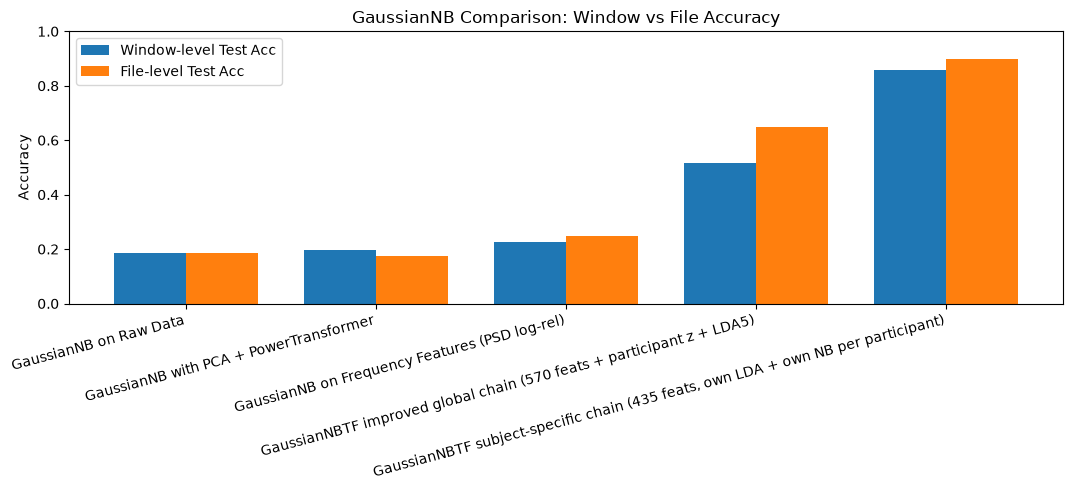

In [16]:
# ============================================================
# Cell 2: Defense chart (Window vs File accuracy side-by-side)
# ============================================================
plot_df = results_df.copy()
plot_df = plot_df.set_index("Experiment").loc[exp_names].reset_index()

x = np.arange(len(plot_df))
w = 0.38

plt.figure(figsize=(11, 5))
plt.bar(x - w/2, plot_df["Test_Acc_Window"], width=w, label="Window-level Test Acc")
plt.bar(x + w/2, plot_df["Test_Acc_File"], width=w, label="File-level Test Acc")
plt.xticks(x, plot_df["Experiment"], rotation=15, ha="right")
plt.ylim(0, 1.0)
plt.ylabel("Accuracy")
plt.title("GaussianNB Comparison: Window vs File Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

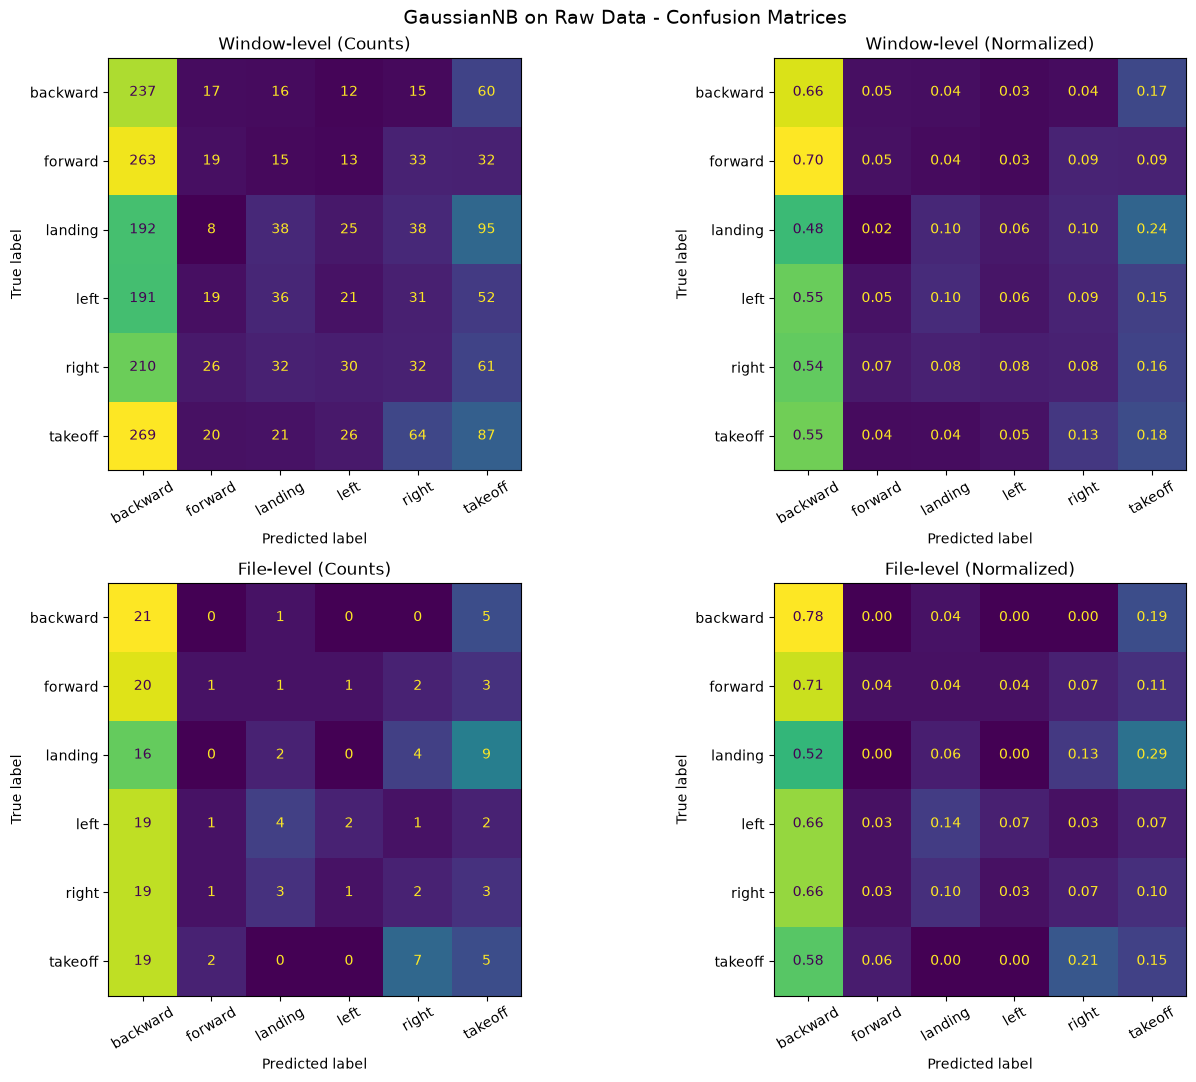

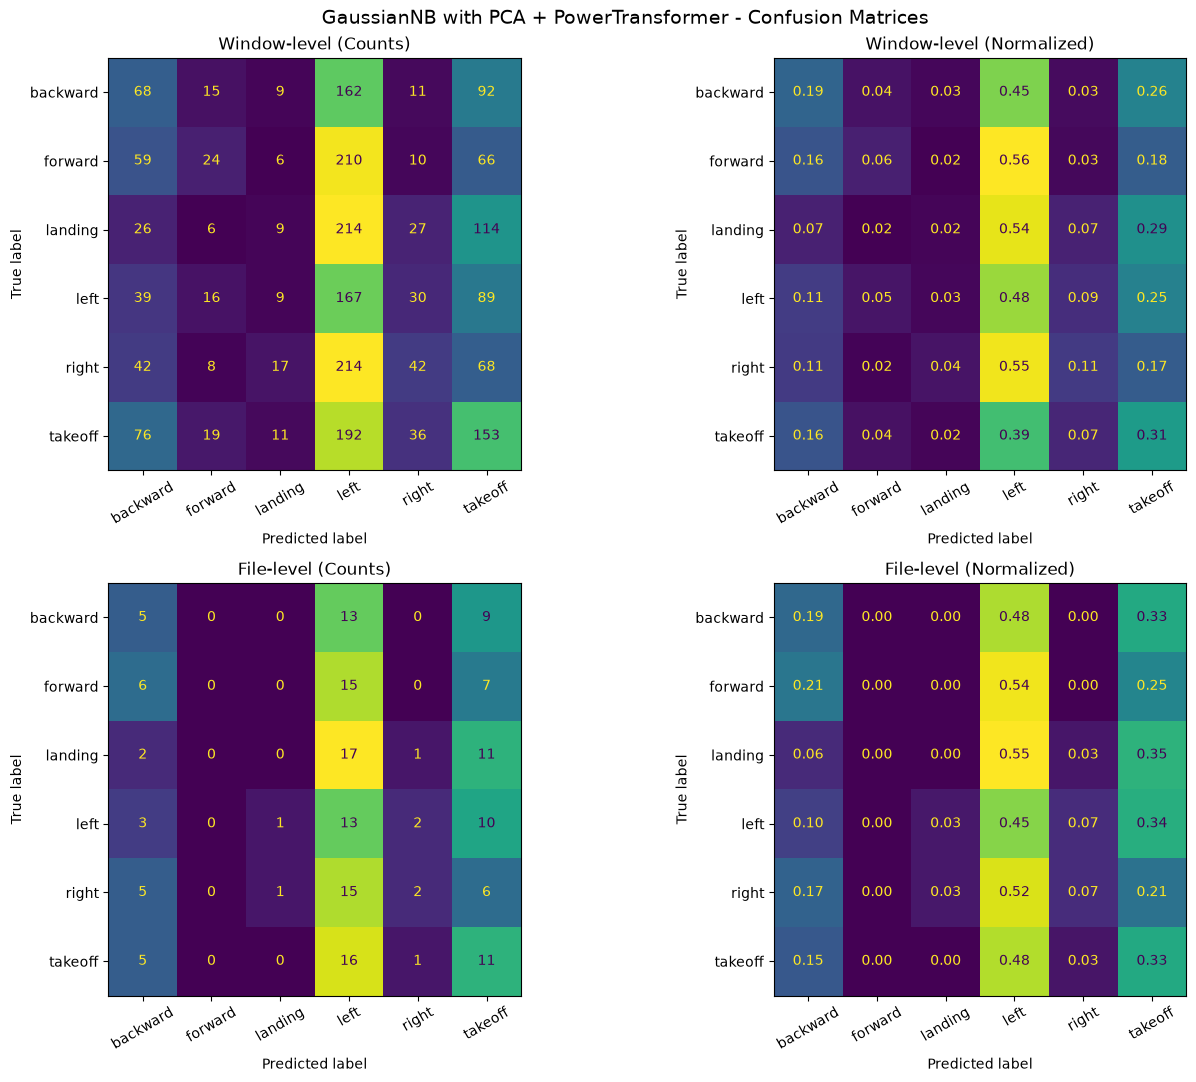

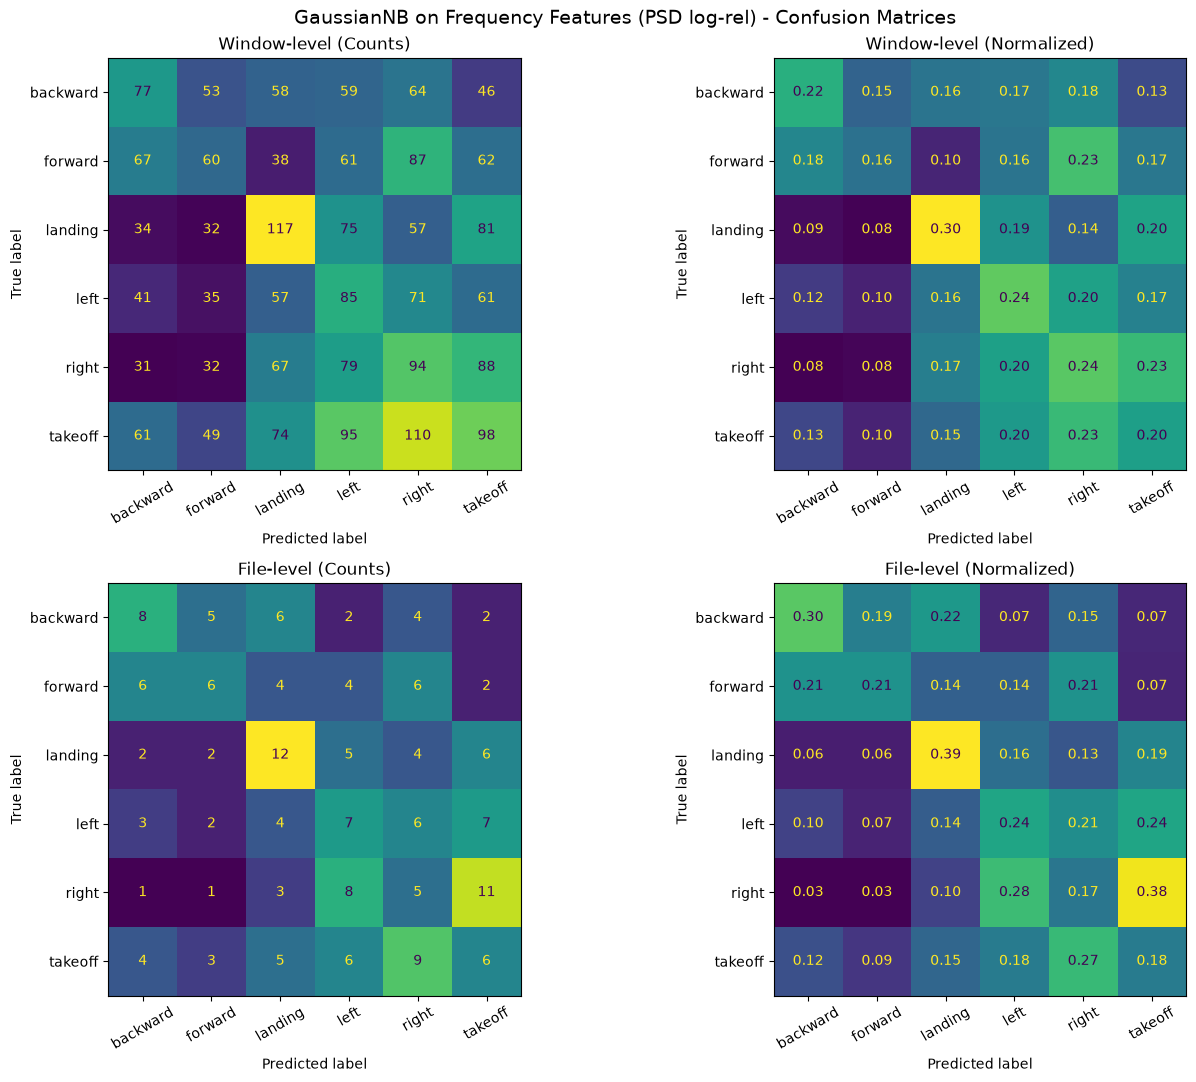

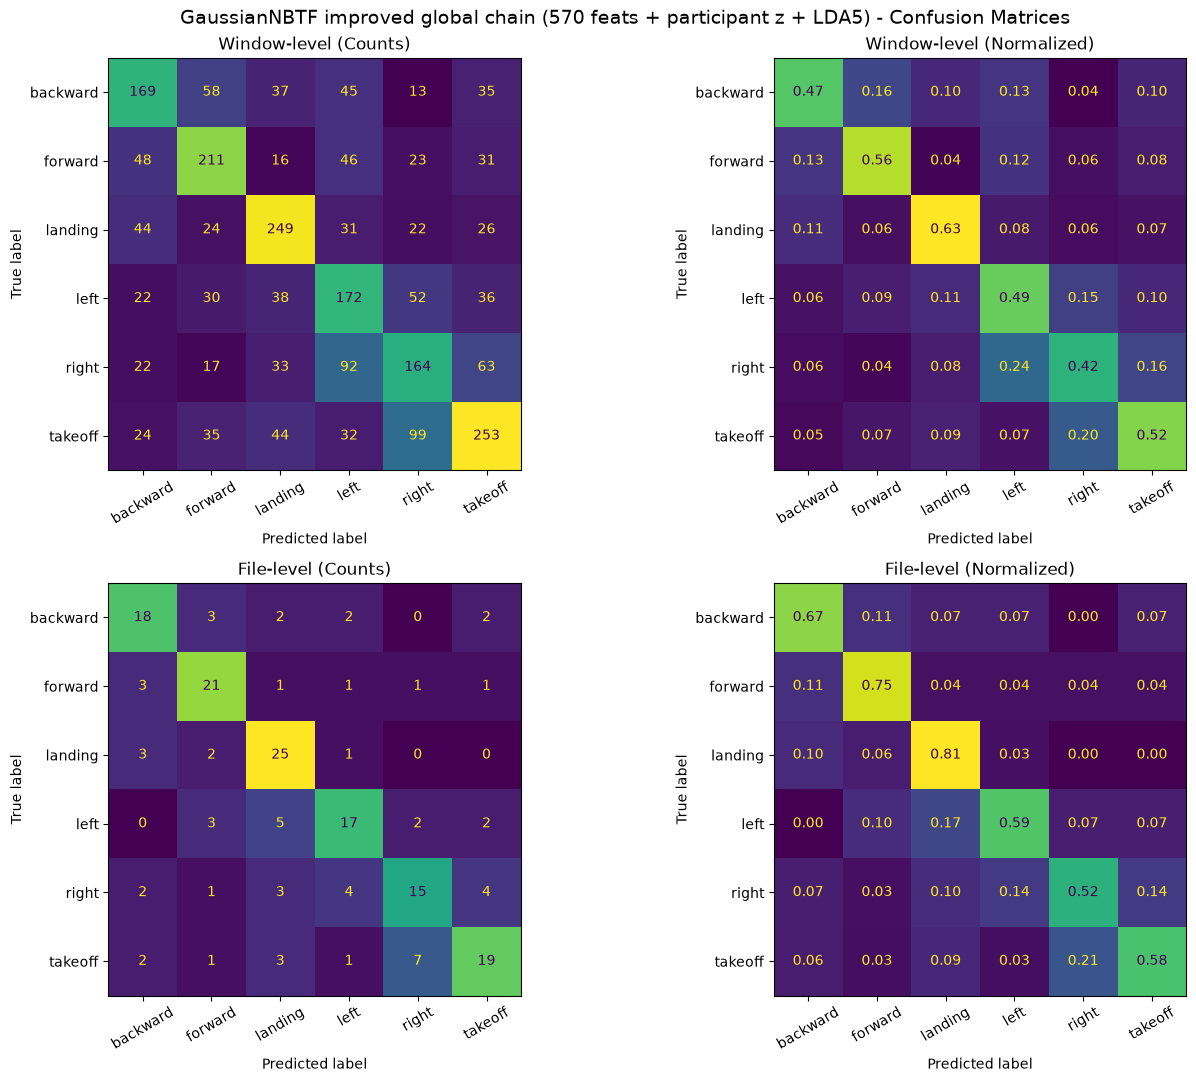

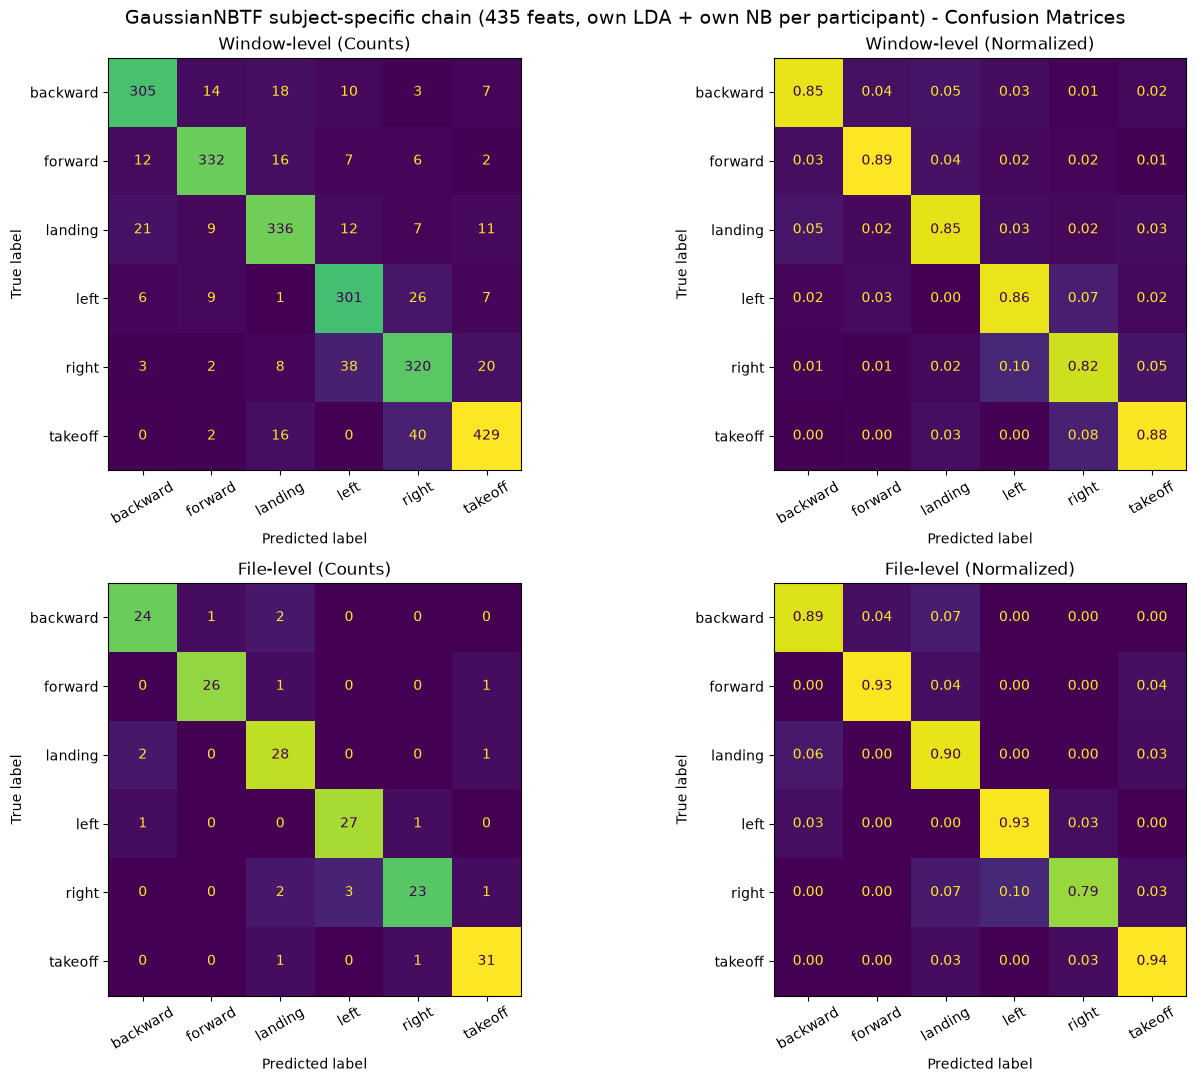

In [17]:
# ============================================================
# Cell 3: Confusion matrices for ALL experiments
# - Window-level (raw counts + normalized)
# - File-level (raw counts + normalized)
# ============================================================
for name, art in artifacts.items():
    y_tw, y_pw = art["y_test"], art["y_pred"]
    y_tf, y_pf = art["y_true_file"], art["y_pred_file"]

    cm_w = confusion_matrix(y_tw, y_pw, labels=np.arange(len(label_names)))
    cm_w_n = confusion_matrix(y_tw, y_pw, labels=np.arange(len(label_names)), normalize="true")

    cm_f = confusion_matrix(y_tf, y_pf, labels=np.arange(len(label_names)))
    cm_f_n = confusion_matrix(y_tf, y_pf, labels=np.arange(len(label_names)), normalize="true")

    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    fig.suptitle(f"{name} - Confusion Matrices", fontsize=14)

    ConfusionMatrixDisplay(cm_w, display_labels=label_names).plot(ax=axes[0, 0], xticks_rotation=30, colorbar=False)
    axes[0, 0].set_title("Window-level (Counts)")

    ConfusionMatrixDisplay(cm_w_n, display_labels=label_names).plot(ax=axes[0, 1], xticks_rotation=30, colorbar=False, values_format=".2f")
    axes[0, 1].set_title("Window-level (Normalized)")

    ConfusionMatrixDisplay(cm_f, display_labels=label_names).plot(ax=axes[1, 0], xticks_rotation=30, colorbar=False)
    axes[1, 0].set_title("File-level (Counts)")

    ConfusionMatrixDisplay(cm_f_n, display_labels=label_names).plot(ax=axes[1, 1], xticks_rotation=30, colorbar=False, values_format=".2f")
    axes[1, 1].set_title("File-level (Normalized)")

    plt.tight_layout()
    plt.show()

,Experiment,Class,Precision,Recall,F1,Support
0,GaussianNB on Raw Data,backward,0.174009,0.663866,0.275742,357.0
1,GaussianNB on Raw Data,forward,0.174312,0.050667,0.078512,375.0
2,GaussianNB on Raw Data,landing,0.240506,0.095960,0.137184,396.0
3,GaussianNB on Raw Data,left,0.165354,0.060000,0.088050,350.0
4,GaussianNB on Raw Data,right,0.150235,0.081841,0.105960,391.0


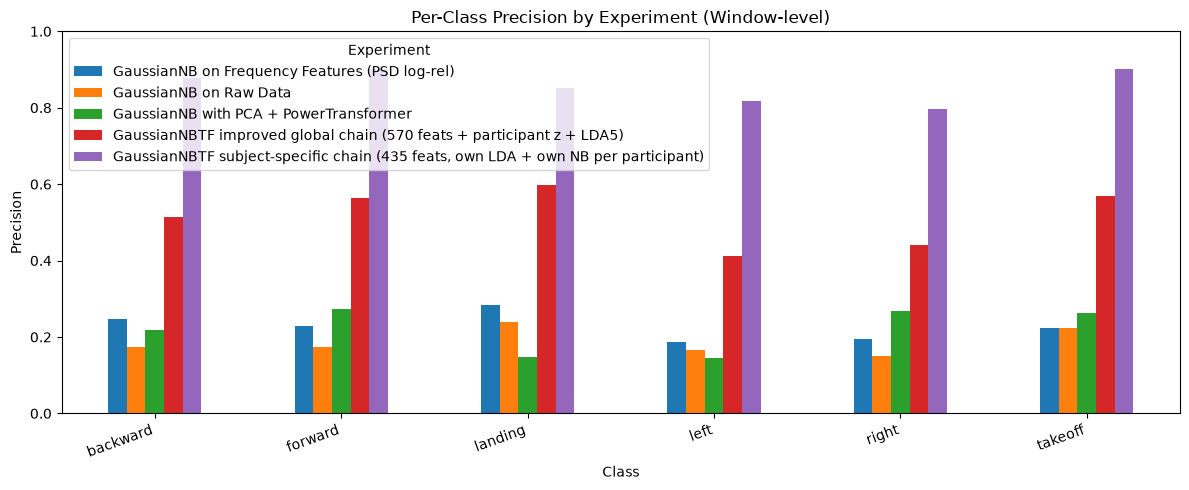

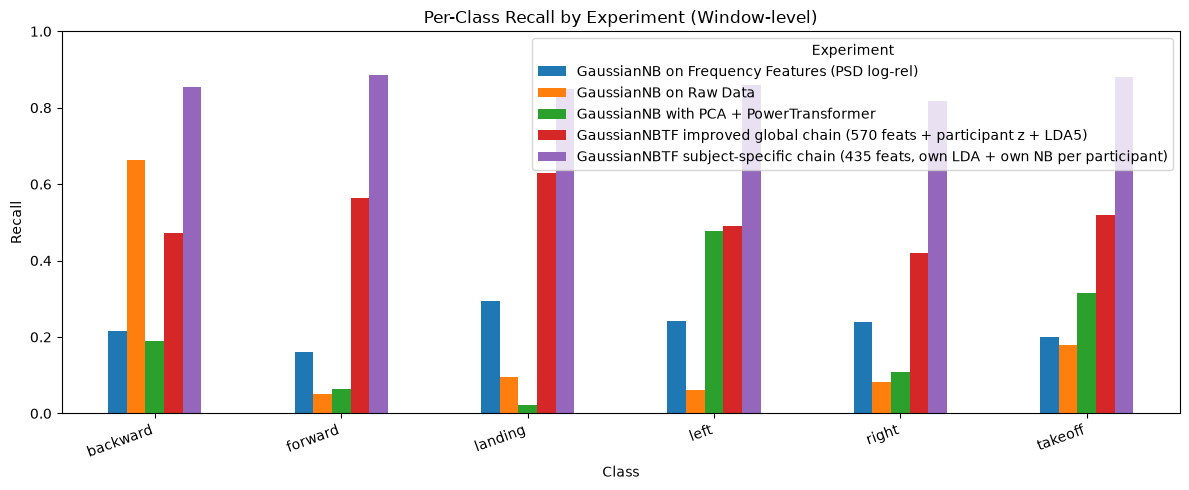

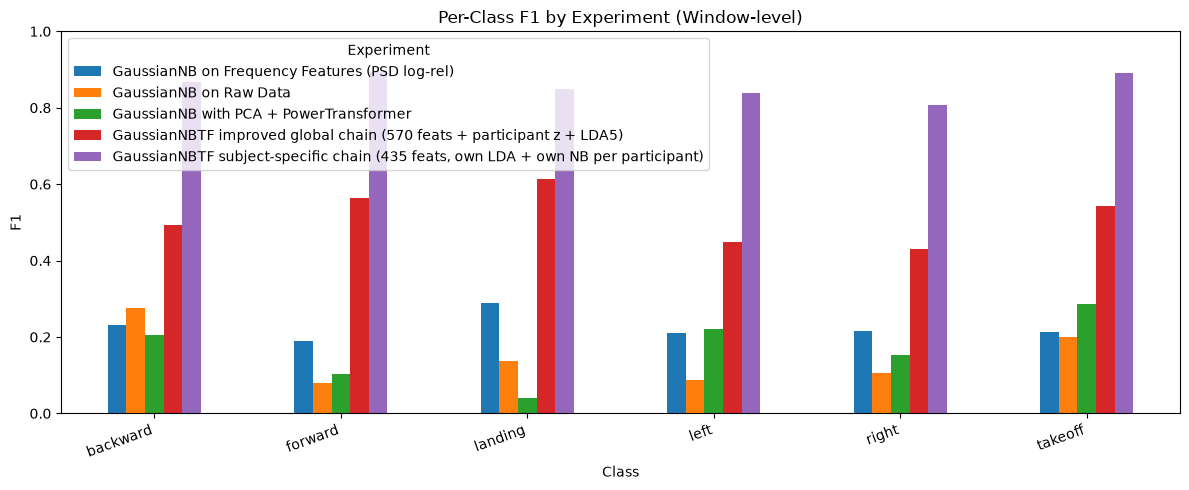

In [18]:
# ============================================================
# Cell 4: Per-class metrics comparison (precision/recall/F1)
# ============================================================
rows = []
for name, art in artifacts.items():
    rep = classification_report(
        art["y_test"], art["y_pred"],
        labels=np.arange(len(label_names)),
        target_names=label_names,
        zero_division=0,
        output_dict=True
    )
    for cls in label_names:
        rows.append({
            "Experiment": name,
            "Class": cls,
            "Precision": rep[cls]["precision"],
            "Recall": rep[cls]["recall"],
            "F1": rep[cls]["f1-score"],
            "Support": rep[cls]["support"]
        })

class_df = pd.DataFrame(rows)
display(class_df.head())

metrics = ["Precision", "Recall", "F1"]
for m in metrics:
    pivot = class_df.pivot(index="Class", columns="Experiment", values=m).reindex(label_names)
    pivot.plot(kind="bar", figsize=(12, 5))
    plt.ylim(0, 1.0)
    plt.ylabel(m)
    plt.title(f"Per-Class {m} by Experiment (Window-level)")
    plt.xticks(rotation=20, ha="right")
    plt.legend(title="Experiment")
    plt.tight_layout()
    plt.show()

In [19]:
# ============================================================
# Cell 5: Full textual reports for ALL experiments
# ============================================================
for name, art in artifacts.items():
    print("=" * 90)
    print(name)
    print("- Window-level classification report")
    print(classification_report(
        art["y_test"], art["y_pred"],
        labels=np.arange(len(label_names)),
        target_names=label_names,
        zero_division=0
    ))
    print("- File-level classification report")
    print(classification_report(
        art["y_true_file"], art["y_pred_file"],
        labels=np.arange(len(label_names)),
        target_names=label_names,
        zero_division=0
    ))

GaussianNB on Raw Data
- Window-level classification report
              precision    recall  f1-score   support

    backward       0.17      0.66      0.28       357
     forward       0.17      0.05      0.08       375
     landing       0.24      0.10      0.14       396
        left       0.17      0.06      0.09       350
       right       0.15      0.08      0.11       391
     takeoff       0.22      0.18      0.20       487

    accuracy                           0.18      2356
   macro avg       0.19      0.19      0.15      2356
weighted avg       0.19      0.18      0.15      2356

- File-level classification report
              precision    recall  f1-score   support

    backward       0.18      0.78      0.30        27
     forward       0.20      0.04      0.06        28
     landing       0.18      0.06      0.10        31
        left       0.50      0.07      0.12        29
       right       0.12      0.07      0.09        29
     takeoff       0.19      0.15    

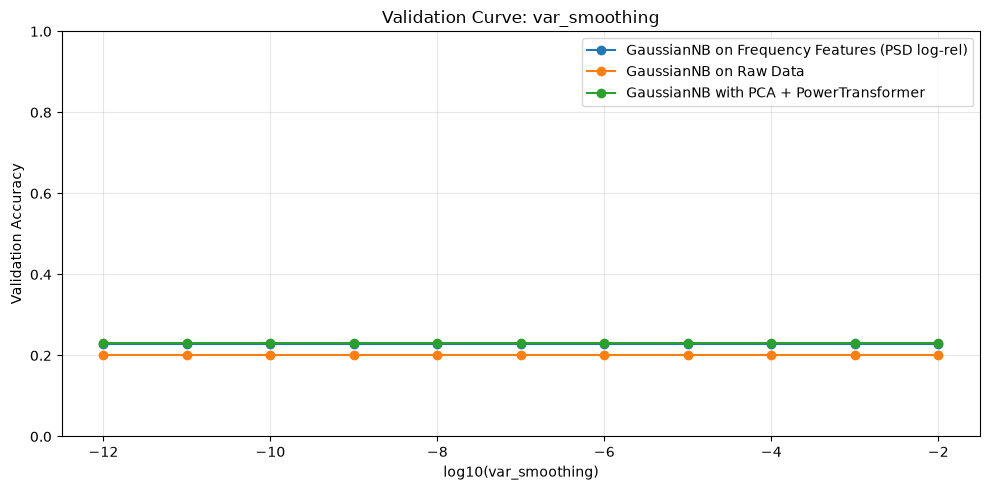

,Experiment,var_smoothing,log10_vs,val_acc
22,GaussianNB on Frequency Features (PSD log-rel),1.000000e-12,-12.0,0.228180
23,GaussianNB on Frequency Features (PSD log-rel),1.000000e-11,-11.0,0.228180
24,GaussianNB on Frequency Features (PSD log-rel),1.000000e-10,-10.0,0.228180
25,GaussianNB on Frequency Features (PSD log-rel),1.000000e-09,-9.0,0.228180
26,GaussianNB on Frequency Features (PSD log-rel),1.000000e-08,-8.0,0.228180
27,GaussianNB on Frequency Features (PSD log-rel),1.000000e-07,-7.0,0.228180
28,GaussianNB on Frequency Features (PSD log-rel),1.000000e-06,-6.0,0.228180
29,GaussianNB on Frequency Features (PSD log-rel),1.000000e-05,-5.0,0.228180
30,GaussianNB on Frequency Features (PSD log-rel),1.000000e-04,-4.0,0.228180
31,GaussianNB on Frequency Features (PSD log-rel),1.000000e-03,-3.0,0.228180


In [20]:
# ============================================================
# Cell 6: Optional var_smoothing curves (requires helper funcs
# and data split vars from your experiment cell to still exist)
# ============================================================
required = [
    "build_window_dataset", "fit_preprocess", "apply_preprocess",
    "GaussianNBTF", "accuracy_score", "train_files", "val_files",
    "train_medians", "window_size", "window_stride", "var_smoothing_grid",
    "feat_raw_flatten", "feat_psd_bands_logrel"
]
missing = [r for r in required if r not in globals()]

if missing:
    print("Skipping var_smoothing curves. Missing symbols:", missing)
else:
    # Match experiments exactly
    exp_cfg = [
        ("GaussianNB on Raw Data", feat_raw_flatten, "none", None),
        ("GaussianNB with PCA + PowerTransformer", feat_raw_flatten, "power", 0.95),
        ("GaussianNB on Frequency Features (PSD log-rel)", feat_psd_bands_logrel, "quantile", 0.95),
    ]

    curves = []
    for name, ff, gz, pca_v in exp_cfg:
        # The experiment cell already computed this exact curve while tuning var_smoothing
        # (same windows, preprocessing and grid), so reuse it instead of recomputing.
        if name in artifacts and "val_curve" in artifacts[name]:
            curve = artifacts[name]["val_curve"]
        else:
            X_tr, y_tr, _, _, _ = build_window_dataset(train_files, train_medians, window_size, window_stride, ff)
            X_va, y_va, _, _, _ = build_window_dataset(val_files, train_medians, window_size, window_stride, ff)
            state, Xtr_p = fit_preprocess(X_tr, gaussianizer=gz, pca_var=pca_v)
            Xva_p = apply_preprocess(X_va, state)
            curve = tune_var_smoothing(Xtr_p, y_tr, Xva_p, y_va, var_smoothing_grid)[2]

        for vs, acc in curve:
            curves.append({
                "Experiment": name,
                "var_smoothing": float(vs),
                "log10_vs": np.log10(float(vs)),
                "val_acc": acc
            })

    curve_df = pd.DataFrame(curves)

    plt.figure(figsize=(10, 5))
    for name, g in curve_df.groupby("Experiment"):
        g = g.sort_values("log10_vs")
        plt.plot(g["log10_vs"], g["val_acc"], marker="o", label=name)

    plt.xlabel("log10(var_smoothing)")
    plt.ylabel("Validation Accuracy")
    plt.title("Validation Curve: var_smoothing")
    plt.ylim(0, 1.0)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(curve_df.sort_values(["Experiment", "var_smoothing"]))

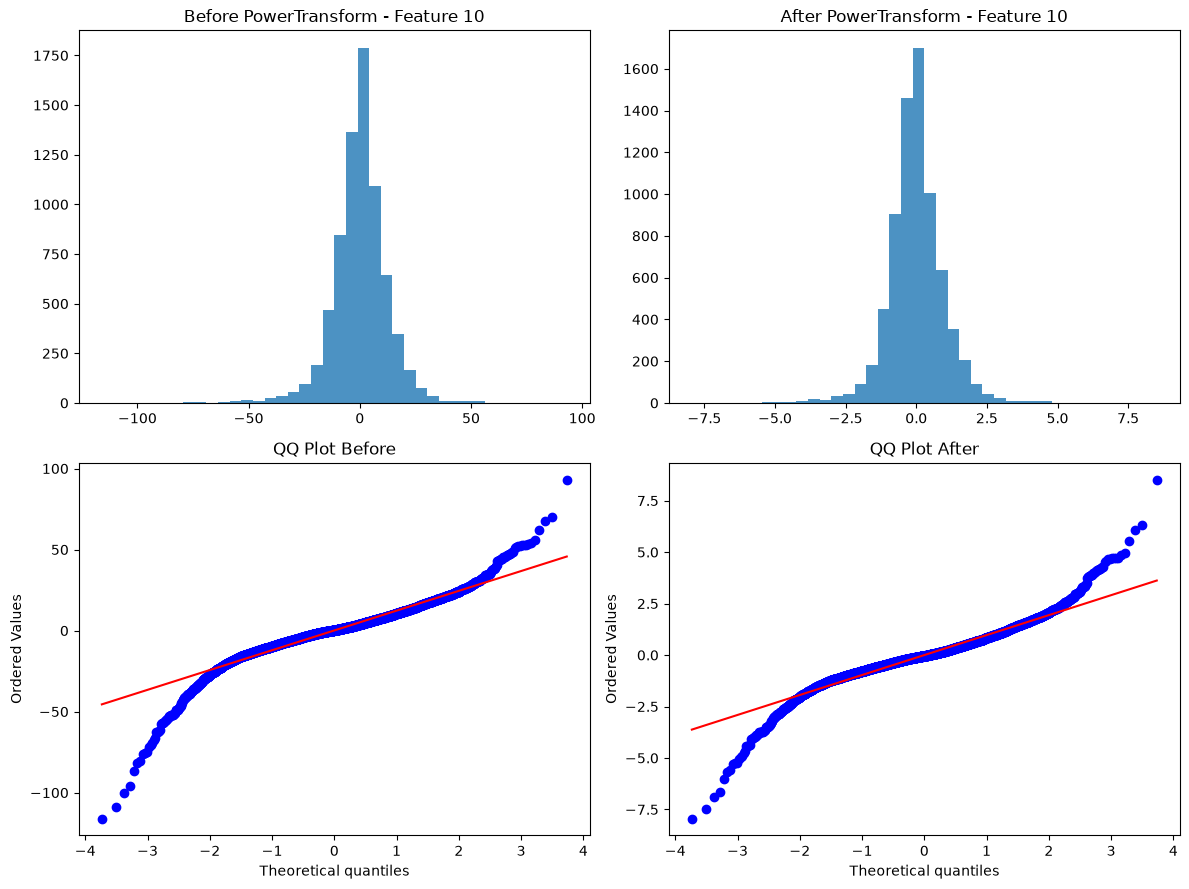

Lower is closer to Gaussian (0 skew, 0 excess kurtosis):


,mean_abs_skew_before,mean_abs_skew_after,mean_abs_kurt_before,mean_abs_kurt_after
0,0.727318,0.141444,14.956028,12.858416


In [21]:
# ============================================================
# Cell 7: Optional Gaussianization evidence (QQ + hist before/after)
# Uses one pipeline to demonstrate normality shift.
# ============================================================
required = [
    "build_window_dataset", "fit_preprocess", "train_files", "train_medians",
    "window_size", "window_stride", "feat_raw_flatten"
]
missing = [r for r in required if r not in globals()]

if missing:
    print("Skipping gaussianization diagnostics. Missing symbols:", missing)
else:
    # Demonstrate on the same raw features used in pipeline 2
    X_tr_raw, y_tr_raw, _, _, _ = build_window_dataset(
        train_files, train_medians, window_size, window_stride, feat_raw_flatten
    )
    # Reuse the PowerTransformer the experiment cell fitted on these same training windows
    power_art = artifacts.get("GaussianNB with PCA + PowerTransformer", {})
    power_state = power_art.get("train_preprocess_state")
    if power_state is not None and power_state["transformer"] is not None:
        X_tr_power = power_state["transformer"].transform(X_tr_raw).astype(np.float32)
    else:
        state_power, X_tr_power = fit_preprocess(X_tr_raw, gaussianizer="power", pca_var=None)

    # Pick a stable feature index
    idx = min(10, X_tr_raw.shape[1] - 1)
    x_before = X_tr_raw[:, idx]
    x_after = X_tr_power[:, idx]

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes[0, 0].hist(x_before, bins=40, alpha=0.8)
    axes[0, 0].set_title(f"Before PowerTransform - Feature {idx}")
    axes[0, 1].hist(x_after, bins=40, alpha=0.8)
    axes[0, 1].set_title(f"After PowerTransform - Feature {idx}")

    stats.probplot(x_before, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title("QQ Plot Before")
    stats.probplot(x_after, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("QQ Plot After")

    plt.tight_layout()
    plt.show()

    # quick skew/kurtosis check on first N features
    N = min(50, X_tr_raw.shape[1])
    skew_before = pd.Series(stats.skew(X_tr_raw[:, :N], axis=0, nan_policy="omit"))
    skew_after = pd.Series(stats.skew(X_tr_power[:, :N], axis=0, nan_policy="omit"))
    kurt_before = pd.Series(stats.kurtosis(X_tr_raw[:, :N], axis=0, nan_policy="omit"))
    kurt_after = pd.Series(stats.kurtosis(X_tr_power[:, :N], axis=0, nan_policy="omit"))

    diag = pd.DataFrame({
        "mean_abs_skew_before": [np.nanmean(np.abs(skew_before))],
        "mean_abs_skew_after": [np.nanmean(np.abs(skew_after))],
        "mean_abs_kurt_before": [np.nanmean(np.abs(kurt_before))],
        "mean_abs_kurt_after": [np.nanmean(np.abs(kurt_after))]
    })
    print("Lower is closer to Gaussian (0 skew, 0 excess kurtosis):")
    display(diag)

In [22]:
results_df = pd.DataFrame(results).sort_values("Test_Acc_File", ascending=False).reset_index(drop=True)

In [23]:
# Reload model module to ensure latest save_model is in scope
import importlib, gaussiannb_model
importlib.reload(gaussiannb_model)
from gaussiannb_model import GaussianNBTF, save_model